# Volatility state vs return state (paper 2)

Figures and numbers for *Inspectable Neural Markov Models for Non-Stationary Time Series*, read from
`results/volatility` (written by `experiments/run_vol.py`). No training.

ΔNLL is `nll_test - log(N)`: negative means better than a uniform forecast over the N quantile bins,
which is the train-period marginal.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "markov").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from markov.data import TICKERS

RES = ROOT / "results/volatility"
FIG = RES / "figures"
MODELS = ["state_free", "state_cond_return", "state_cond_vol_w5", "state_cond_vol_w10", "state_cond_vol_w21", "state_cond_macro"]
SEEDS = [42, 7, 123]
COLORS = dict(zip(TICKERS, plt.cm.tab10.colors))
W1, W2 = 3.5, 7.0
plt.rcParams.update({"font.size": 11, "axes.grid": True, "grid.color": "#e0e0e0", "grid.linewidth": 0.5,
                     "figure.dpi": 150, "savefig.dpi": 300, "savefig.bbox": "tight"})


def save(fig, stem):
    FIG.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIG / f"{stem}.pdf")
    fig.savefig(FIG / f"{stem}.png")
    plt.show()


nll = pd.concat([pd.read_csv(RES / t / m / "nll_metrics.csv") for t in TICKERS for m in MODELS], ignore_index=True)
states = {t: pd.read_csv(RES / f"vol_state_ts_{t}.csv", parse_dates=["date"]) for t in TICKERS}
h1 = nll[(nll.h == 1) & (nll.N == 55)]
print(len(nll), "runs")

2160 runs


## Table 1 and 2: pooled test NLL

In [2]:
t1 = h1.groupby("model")[["nll_test", "delta_marginal"]].mean().sort_values("nll_test")
t2 = nll[nll.N == 55].groupby(["model", "h"]).nll_test.mean().unstack()
t3 = nll[nll.h == 1].groupby(["model", "N"]).nll_test.mean().unstack()
for name, t in [("table1_h1_N55", t1), ("table2_by_horizon_N55", t2), ("table3_by_bins_h1", t3)]:
    t.round(4).to_csv(RES / f"{name}.csv")
print(t1.round(4), "\n")
print(t2.round(4))

                    nll_test  delta_marginal
model                                       
state_cond_vol_w21    3.9847         -0.0226
state_cond_vol_w10    3.9864         -0.0209
state_free            3.9930         -0.0143
state_cond_macro      3.9938         -0.0135
state_cond_return     3.9942         -0.0131
state_cond_vol_w5     3.9955         -0.0119 

h                        1       2       3       5
model                                             
state_cond_macro    3.9938  4.0091  4.0185  4.0126
state_cond_return   3.9942  4.0130  4.0168  4.0162
state_cond_vol_w10  3.9864  4.0057  4.0133  4.0090
state_cond_vol_w21  3.9847  4.0040  4.0089  4.0078
state_cond_vol_w5   3.9955  4.0101  4.0181  4.0164
state_free          3.9930  4.0110  4.0188  4.0173


In [3]:
per = h1.groupby(["ticker", "model"]).delta_marginal.mean().unstack()
wins = per.state_cond_vol_w21 < per.state_cond_return
print(f"vol_w21 beats the return state in {wins.sum()} of 10 banks, losers: {list(per.index[~wins])}")
print(f"pooled gap return - vol_w21: {per.state_cond_return.mean() - per.state_cond_vol_w21.mean():.4f} nats")
for h in [2, 3, 5]:
    print(f"h={h} gap: {t2.loc['state_cond_return', h] - t2.loc['state_cond_vol_w21', h]:.4f}")

vol_w21 beats the return state in 9 of 10 banks, losers: ['PNC']
pooled gap return - vol_w21: 0.0095 nats
h=2 gap: 0.0090
h=3 gap: 0.0080
h=5 gap: 0.0084


## Chapman-Kolmogorov discrepancy, vol state vs return state

Here the h-step operator maps the state to the h-day return bin and the 1-step operators map the state to
the 1-day return bin, so the "composition" treats a return bin as the next state. For the return state
that is roughly the same variable, for the vol state it is not.

In [4]:
rows = []
for t in TICKERS:
    for m in ["state_cond_return", "state_cond_vol_w21"]:
        for h in [2, 3, 5]:
            for seed in SEEDS:
                rows.append({"ticker": t, "model": m, "h": h, "seed": seed,
                             "ck_kl": pd.read_csv(RES / t / m / f"ck_ts_h{h}_N55_seed{seed}.csv").ck_kl.mean()})
ck = pd.DataFrame(rows)
for label, sub in [("seed 42 only", ck[ck.seed == 42]), ("mean of 3 seeds", ck)]:
    g = sub[sub.h == 5].groupby(["ticker", "model"]).ck_kl.mean().unstack()
    r, v = g.state_cond_return.mean(), g.state_cond_vol_w21.mean()
    print(f"h=5, {label}: return {r:.4f}, vol_w21 {v:.4f}, reduction {100 * (r - v) / r:.1f}%, "
          f"return higher in {(g.state_cond_return > g.state_cond_vol_w21).sum()} of 10")
g = ck.groupby(["h", "model"]).ck_kl.mean().unstack()
print((g.assign(reduction_pct=100 * (g.state_cond_return - g.state_cond_vol_w21) / g.state_cond_return)).round(4))
print("test period:", pd.read_csv(RES / "JPM/state_cond_vol_w21/ck_ts_h5_N55_seed42.csv").date.agg(["min", "max"]).tolist())

h=5, seed 42 only: return 0.0657, vol_w21 0.0620, reduction 5.5%, return higher in 8 of 10
h=5, mean of 3 seeds: return 0.0747, vol_w21 0.0691, reduction 7.5%, return higher in 8 of 10
model  state_cond_return  state_cond_vol_w21  reduction_pct
h                                                          
2                 0.0524              0.0513         1.9925
3                 0.0619              0.0583         5.8389
5                 0.0747              0.0691         7.5129
test period: ['2020-04-23', '2023-12-21']


## Realized volatility vs row entropy, every bank, window and horizon (seed 42, N=55)

In [5]:
rows = []
for t in TICKERS:
    for w in [5, 10, 21]:
        for h in [1, 2, 3, 5]:
            op = pd.read_csv(RES / t / f"state_cond_vol_w{w}/operator_ts_h{h}_N55_seed42.csv", parse_dates=["date"])
            d = op.merge(states[t][["date", f"sigma_t_w{w}"]], on="date").dropna()
            r, p = stats.pearsonr(d[f"sigma_t_w{w}"], d.row_entropy)
            rows.append({"ticker": t, "window": w, "h": h, "r": r, "p": p, "n": len(d)})
corr = pd.DataFrame(rows)
corr.to_csv(RES / "vol_entropy_correlations.csv", index=False)
print(f"{len(corr)} configs: r < 0 in {(corr.r < 0).sum()}, significant and negative in {((corr.r < 0) & (corr.p < 0.05)).sum()}, "
      f"mean r {corr.r.mean():.3f}")
print(corr.sort_values("r").head(5).round(4).to_string(index=False))

120 configs: r < 0 in 119, significant and negative in 105, mean r -0.264
ticker  window  h       r   p   n
   WFC      10  3 -0.5358 0.0 924
   WFC      10  2 -0.5131 0.0 925
   WFC      10  5 -0.5122 0.0 924
   WFC      21  3 -0.4965 0.0 924
   WFC      21  2 -0.4872 0.0 925


## Fig V1: ΔNLL per bank, h=1, N=55 (error bars = 1.96 SE over seeds)

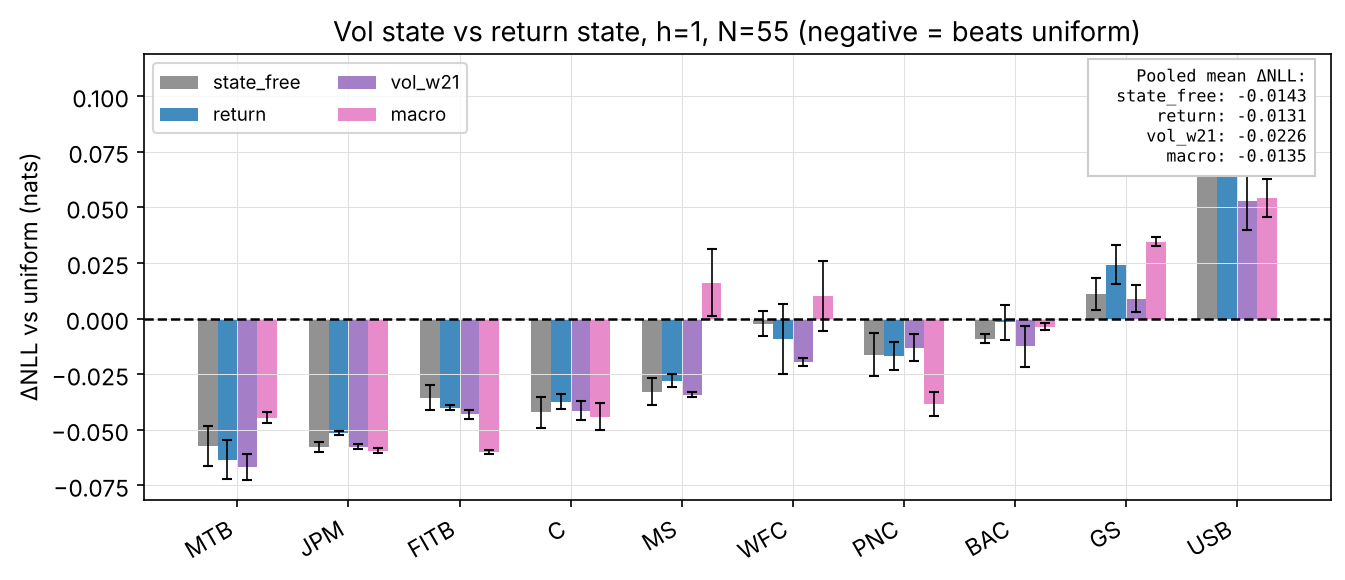

In [6]:
models = ["state_free", "state_cond_return", "state_cond_vol_w21", "state_cond_macro"]
labels = ["state_free", "return", "vol_w21", "macro"]
agg = h1[h1.model.isin(models)].groupby(["ticker", "model"]).delta_marginal.agg(["mean", "std", "count"])
order = agg.xs("state_cond_vol_w21", level="model")["mean"].sort_values().index
fig, ax = plt.subplots(figsize=(W2 * 1.3, 4.0))
x = np.arange(len(order))
for i, (m, label, color) in enumerate(zip(models, labels, ["#7f7f7f", "#1f77b4", "#9467bd", "#e377c2"])):
    a = agg.xs(m, level="model").loc[order]
    ax.bar(x + (i - 1.5) * 0.18, a["mean"], 0.18, label=label, color=color, alpha=0.85,
           yerr=1.96 * a["std"] / np.sqrt(a["count"]), error_kw={"elinewidth": 0.8, "capsize": 2.5})
ax.axhline(0, color="black", lw=1.2, ls="--")
ax.set(xticks=x, ylabel="ΔNLL vs uniform (nats)", title="Vol state vs return state, h=1, N=55 (negative = beats uniform)")
ax.set_xticklabels(order, rotation=30, ha="right")
pooled = agg["mean"].groupby("model").mean()
ax.text(0.98, 0.97, "Pooled mean ΔNLL:\n" + "\n".join(f"  {l}: {pooled[m]:+.4f}" for m, l in zip(models, labels)),
        transform=ax.transAxes, va="top", ha="right", fontsize=8, family="monospace", bbox={"facecolor": "white", "edgecolor": "#ccc"})
ax.legend(fontsize=9, ncol=2)
fig.tight_layout()
save(fig, "fig_V1_headtohead")

## Fig V2: vol window comparison, JPM

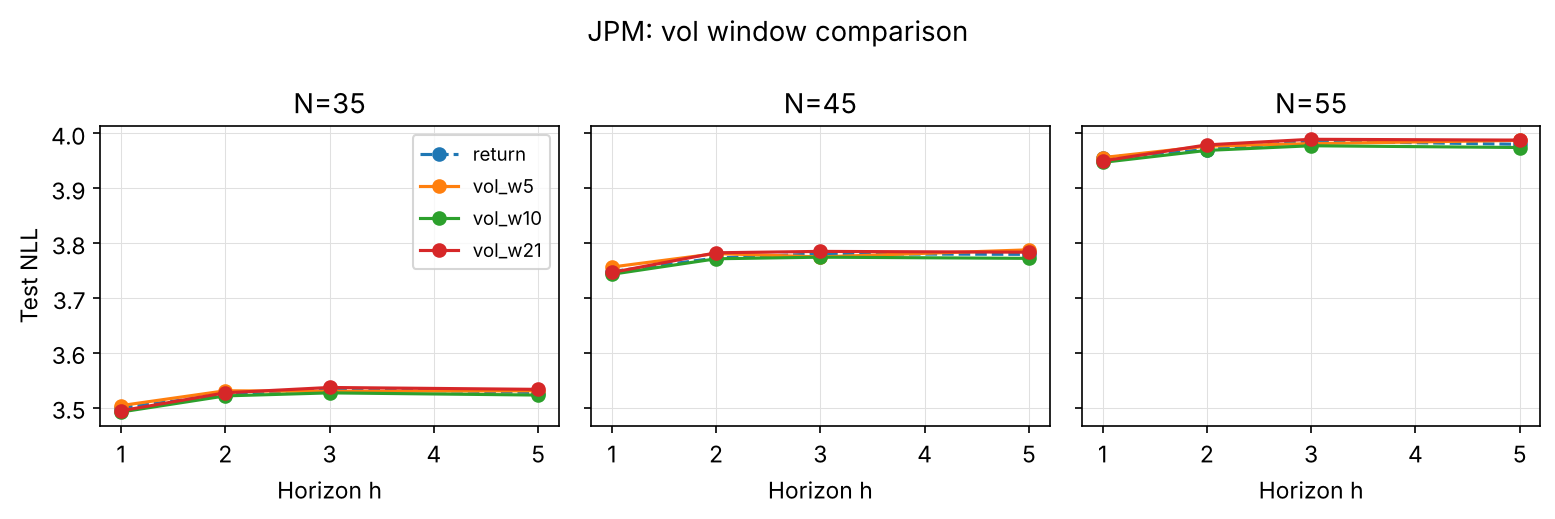

In [7]:
jpm = nll[nll.ticker == "JPM"]
fig, axes = plt.subplots(1, 3, figsize=(W2 * 1.5, 3.5), sharey=True)
for ax, N in zip(axes, [35, 45, 55]):
    for m, color, ls in [("state_cond_return", "#1f77b4", "--"), ("state_cond_vol_w5", "#ff7f0e", "-"),
                         ("state_cond_vol_w10", "#2ca02c", "-"), ("state_cond_vol_w21", "#d62728", "-")]:
        g = jpm[(jpm.N == N) & (jpm.model == m)].groupby("h").nll_test.mean()
        ax.plot(g.index, g.values, marker="o", color=color, ls=ls, label=m.replace("state_cond_", ""))
    ax.set(title=f"N={N}", xlabel="Horizon h")
axes[0].set_ylabel("Test NLL")
axes[0].legend(fontsize=9)
fig.suptitle("JPM: vol window comparison")
fig.tight_layout()
save(fig, "fig_V2_vol_window_JPM")

## Fig V3: σ_t vs row entropy, WFC (window 10, h=1, N=55, seed 42), the case in paper 2 figure 4

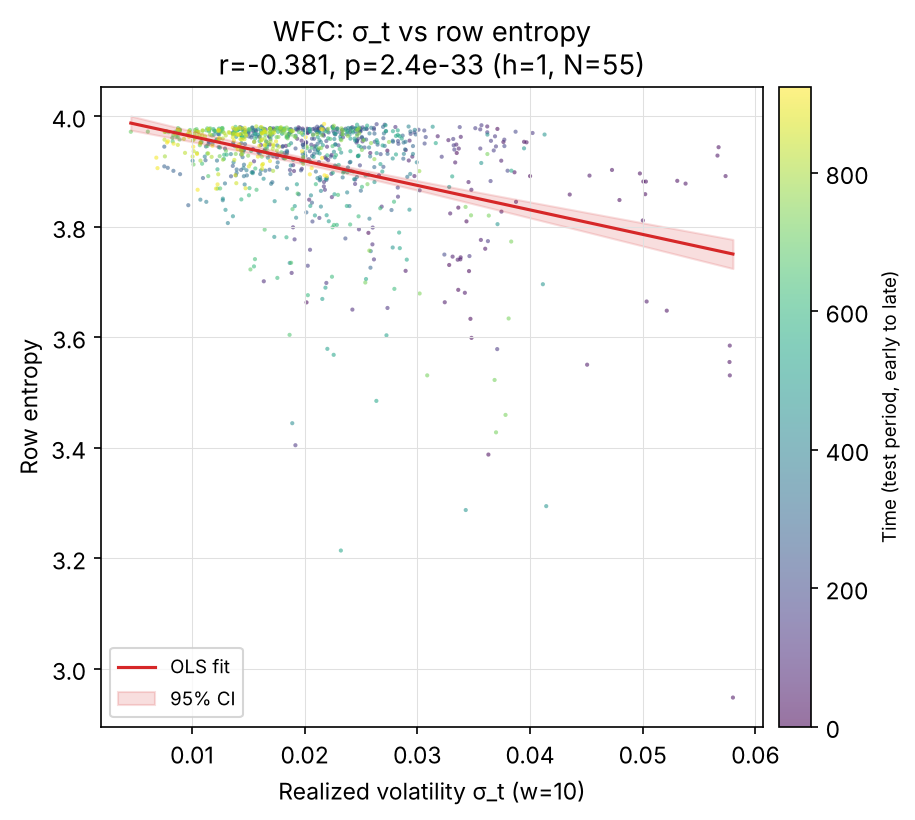

In [8]:
op = pd.read_csv(RES / "WFC/state_cond_vol_w10/operator_ts_h1_N55_seed42.csv", parse_dates=["date"])
d = op.merge(states["WFC"][["date", "sigma_t_w10"]], on="date").dropna()
x, y = d.sigma_t_w10.values, d.row_entropy.values
r, p = stats.pearsonr(x, y)
fit = stats.linregress(x, y)
xs = np.linspace(x.min(), x.max(), 200)
se = np.sqrt(np.sum((y - fit.intercept - fit.slope * x) ** 2) / (len(x) - 2)) * np.sqrt(1 / len(x) + (xs - x.mean()) ** 2 / np.sum((x - x.mean()) ** 2))
fig, ax = plt.subplots(figsize=(W1 * 1.8, W1 * 1.6))
sc = ax.scatter(x, y, c=np.arange(len(x)), cmap="viridis", s=4, alpha=0.55, lw=0)
fig.colorbar(sc, ax=ax, pad=0.02).set_label("Time (test period, early to late)", fontsize=9)
ax.plot(xs, fit.intercept + fit.slope * xs, color="#d62728", lw=1.5, label="OLS fit")
ax.fill_between(xs, fit.intercept + fit.slope * xs - 1.96 * se, fit.intercept + fit.slope * xs + 1.96 * se, color="#d62728", alpha=0.15, label="95% CI")
ax.set(xlabel="Realized volatility σ_t (w=10)", ylabel="Row entropy", title=f"WFC: σ_t vs row entropy\nr={r:.3f}, p={p:.1e} (h=1, N=55)")
ax.legend(fontsize=9)
fig.tight_layout()
save(fig, "fig_V3_vol_entropy_scatter")

## Fig V4: operator snapshots, return state vs vol state (JPM, h=1, N=55, seed 42)

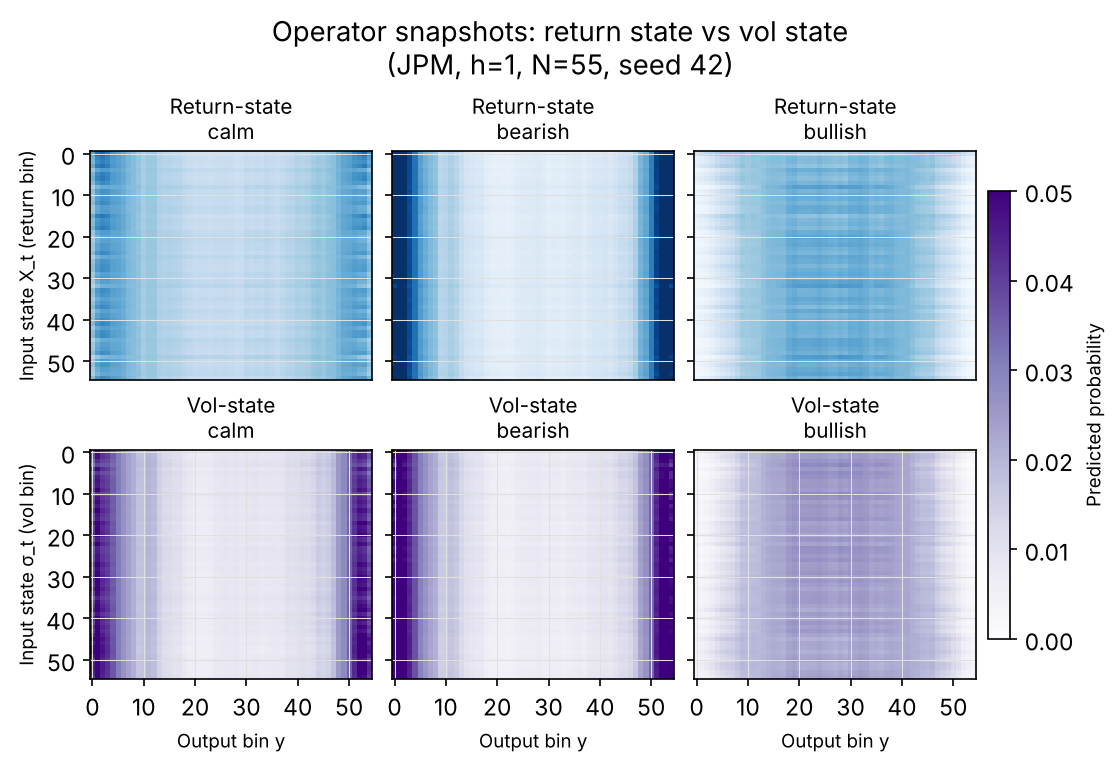

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(W2 * 1.05, 5.0), constrained_layout=True)
for row, (m, cmap, ylabel) in enumerate([("state_cond_return", "Blues", "Input state X_t (return bin)"),
                                         ("state_cond_vol_w21", "Purples", "Input state σ_t (vol bin)")]):
    for col, s in enumerate(["calm", "bearish", "bullish"]):
        im = axes[row, col].imshow(np.load(RES / "JPM" / m / f"snapshots/operator_snapshot_{s}_seed42.npy"), aspect="auto", vmin=0, vmax=0.05, cmap=cmap)
        axes[row, col].set_title(f"{'Return' if row == 0 else 'Vol'}-state\n{s}", fontsize=10)
        axes[row, col].set(xticks=[] if row == 0 else [0, 10, 20, 30, 40, 50], yticks=[0, 10, 20, 30, 40, 50])
        if col:
            axes[row, col].set_yticklabels([])
    axes[row, 0].set_ylabel(ylabel, fontsize=9)
    for ax in axes[1]:
        ax.set_xlabel("Output bin y", fontsize=9)
fig.colorbar(im, ax=axes[:, 2], shrink=0.85, pad=0.04).set_label("Predicted probability", fontsize=9)
fig.suptitle("Operator snapshots: return state vs vol state\n(JPM, h=1, N=55, seed 42)")
save(fig, "fig_V4_snapshots_comparison")

## Fig V5: row entropy of the vol-state model across banks (test period, h=1, N=55, seed 42)

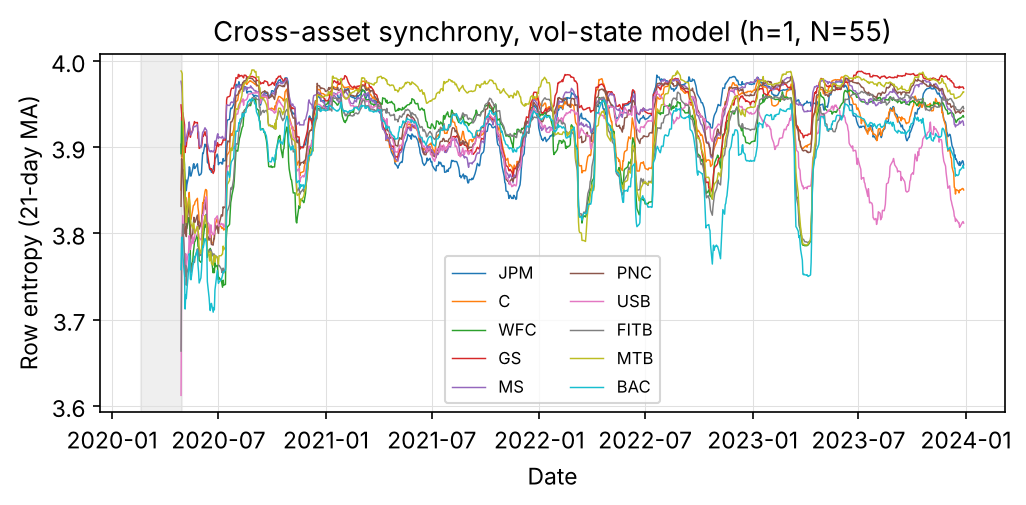

mean pairwise correlation of row entropy: 0.648 (21-day MA: 0.619), 2020-04-28 to 2023-12-28


In [10]:
ent = pd.concat({t: pd.read_csv(RES / t / "state_cond_vol_w21/operator_ts_h1_N55_seed42.csv", parse_dates=["date"]).set_index("date").row_entropy
                 for t in TICKERS}, axis=1)
fig, ax = plt.subplots(figsize=(W2, 3.5))
for t in TICKERS:
    ax.plot(ent.index, ent[t].rolling(21, min_periods=1).mean(), color=COLORS[t], lw=0.7, label=t)
ax.axvspan(pd.Timestamp("2020-02-20"), pd.Timestamp("2020-04-30"), alpha=0.12, color="gray")
ax.set(xlabel="Date", ylabel="Row entropy (21-day MA)", title="Cross-asset synchrony, vol-state model (h=1, N=55)")
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
save(fig, "fig_V5_crossasset_vol")
c = ent.corr().values[np.triu_indices(10, 1)].mean()
c21 = ent.rolling(21, min_periods=1).mean().corr().values[np.triu_indices(10, 1)].mean()
print(f"mean pairwise correlation of row entropy: {c:.3f} (21-day MA: {c21:.3f}), {ent.index.min().date()} to {ent.index.max().date()}")

## Fig V6: test NLL vs horizon per bank (N=55)

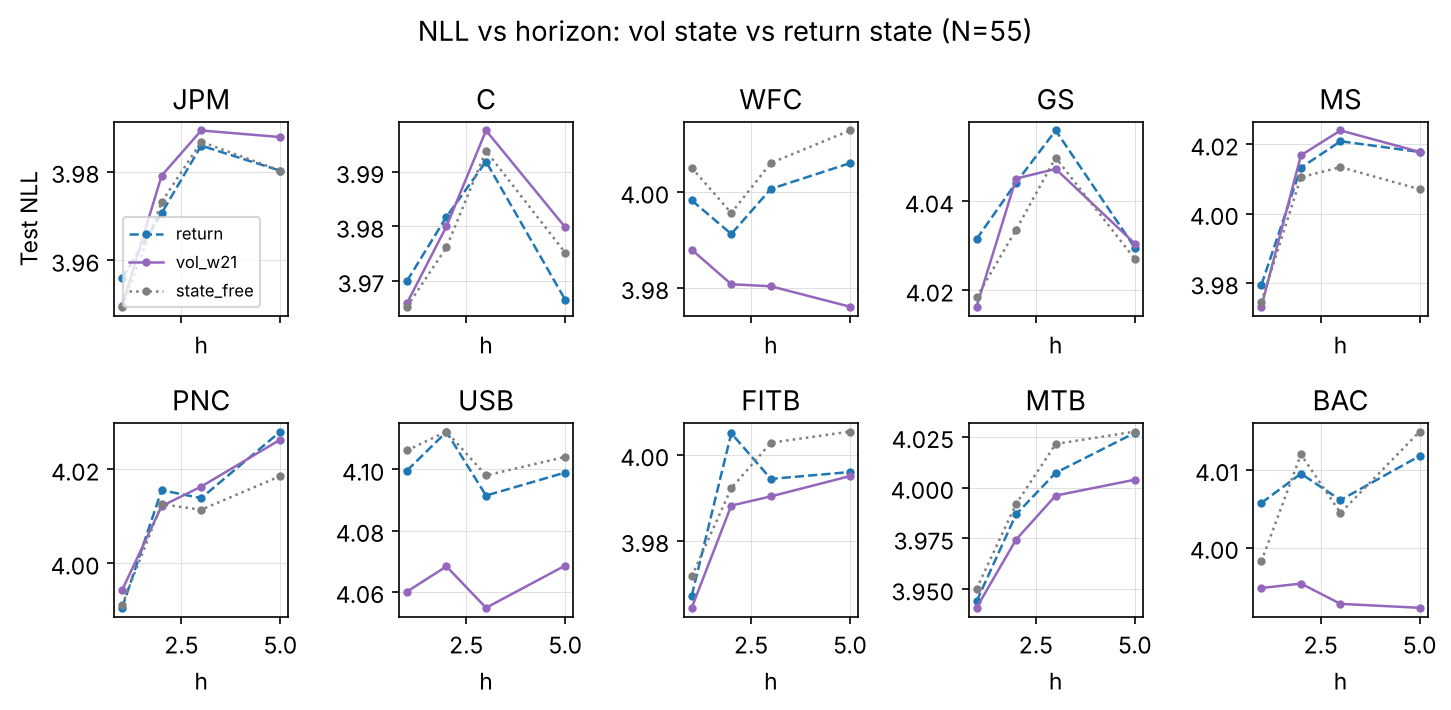

In [11]:
fig, axes = plt.subplots(2, 5, figsize=(W2 * 1.4, 4.8), sharex=True)
for ax, t in zip(axes.flat, TICKERS):
    for m, color, ls in [("state_cond_return", "#1f77b4", "--"), ("state_cond_vol_w21", "#9467bd", "-"), ("state_free", "#7f7f7f", ":")]:
        g = nll[(nll.ticker == t) & (nll.N == 55) & (nll.model == m)].groupby("h").nll_test.mean()
        ax.plot(g.index, g.values, color=color, ls=ls, marker="o", ms=3, lw=1.2, label=m.replace("state_cond_", ""))
    ax.set(title=t, xlabel="h")
axes[0, 0].set_ylabel("Test NLL")
axes[0, 0].legend(fontsize=8)
fig.suptitle("NLL vs horizon: vol state vs return state (N=55)")
fig.tight_layout()
save(fig, "fig_V6_nll_horizon_grid")

## Fig V7: paired comparison per bank (h=1, N=55, mean over seeds)

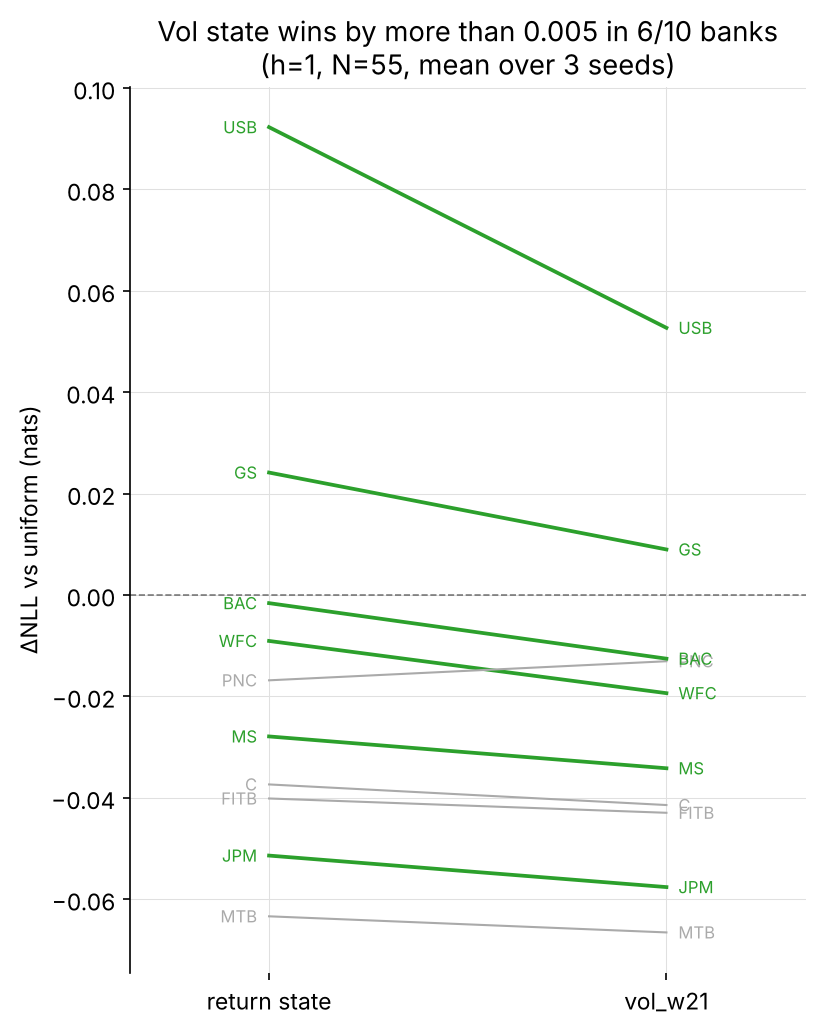

In [12]:
p = per.sort_values("state_cond_vol_w21")
fig, ax = plt.subplots(figsize=(W1 * 1.6, W1 * 2.0))
for t, r_, v_ in zip(p.index, p.state_cond_return, p.state_cond_vol_w21):
    color = "#2ca02c" if v_ - r_ < -0.005 else "#d62728" if r_ - v_ < -0.005 else "#aaaaaa"
    ax.plot([0, 1], [r_, v_], color=color, lw=1.8 if color != "#aaaaaa" else 1.0)
    ax.text(-0.03, r_, t, ha="right", va="center", fontsize=8, color=color)
    ax.text(1.03, v_, t, ha="left", va="center", fontsize=8, color=color)
ax.axhline(0, color="black", lw=0.8, ls="--", alpha=0.5)
n_win = int((p.state_cond_vol_w21 - p.state_cond_return < -0.005).sum())
ax.set(xlim=(-0.35, 1.35), xticks=[0, 1], ylabel="ΔNLL vs uniform (nats)",
       title=f"Vol state wins by more than 0.005 in {n_win}/10 banks\n(h=1, N=55, mean over 3 seeds)")
ax.set_xticklabels(["return state", "vol_w21"])
for s in ["top", "right", "bottom"]:
    ax.spines[s].set_visible(False)
fig.tight_layout()
save(fig, "fig_V7_slope_chart")